# Pipeline de entrenamiento y validación en PyTorch (MNIST)
Checkpoint 1 del Proyecto Final: entorno, datos, clasificador base, ciclo de entrenamiento y validación.

In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Dispositivo:", device)

PyTorch: 2.11.0+cpu
Dispositivo: cpu


In [2]:
#Cargamos data de MNIST
from torchvision import datasets, transforms
from torch.utils.data import random_split

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train = datasets.MNIST(root="data", train=True, download=True, transform=transform)

generator = torch.Generator().manual_seed(SEED)
train_ds, val_ds = random_split(full_train, [54000, 6000], generator=generator)

print("Entrenamiento:", len(train_ds))
print("Validación:", len(val_ds))


Entrenamiento: 54000
Validación: 6000


In [3]:
#Sacamos datos por tandas con Dataloader
from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

images, labels = next(iter(train_loader))
print("Forma de un lote de imágenes:", images.shape)
print("Forma de un lote de etiquetas:", labels.shape)
print("Lotes por época (entrenamiento):", len(train_loader))
print("Lotes por época (validación):", len(val_loader))

Forma de un lote de imágenes: torch.Size([64, 1, 28, 28])
Forma de un lote de etiquetas: torch.Size([64])
Lotes por época (entrenamiento): 844
Lotes por época (validación): 94


In [4]:
#modelo nn.Module
class MLP(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=128, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = MLP().to(device)
print(model)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Parámetros entrenables:", n_params)

with torch.no_grad():
    salida = model(images.to(device))
print("Forma de la salida:", salida.shape)

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parámetros entrenables: 101770
Forma de la salida: torch.Size([64, 10])


In [5]:
#ciclo de entrenamiento
LEARNING_RATE = 1e-3

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        outputs = model(x)
        loss = criterion(outputs, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * x.size(0)
        correct += (outputs.argmax(dim=1) == y).sum().item()
        total += y.size(0)

    return running_loss / total, correct / total


with torch.no_grad():
    loss_inicial = criterion(model(images.to(device)), labels.to(device))
print("Pérdida inicial:", round(loss_inicial.item(), 3))

Pérdida inicial: 2.299


In [6]:
#función de validación
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            outputs = model(x)
            loss = criterion(outputs, y)

            running_loss += loss.item() * x.size(0)
            correct += (outputs.argmax(dim=1) == y).sum().item()
            total += y.size(0)

    return running_loss / total, correct / total


val_loss_inicial, val_acc_inicial = evaluate(model, val_loader, criterion, device)
print("Validación inicial -> pérdida:", round(val_loss_inicial, 3), "| accuracy:", round(val_acc_inicial, 3))

Validación inicial -> pérdida: 2.283 | accuracy: 0.111


In [7]:
#entrenamiento completo
EPOCHS = 10

torch.manual_seed(SEED)
model = MLP().to(device)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Época {epoch:02d}/{EPOCHS} | "
          f"train loss: {train_loss:.4f} acc: {train_acc:.4f} | "
          f"val loss: {val_loss:.4f} acc: {val_acc:.4f}")


Época 01/10 | train loss: 0.2679 acc: 0.9216 | val loss: 0.1648 acc: 0.9498
Época 02/10 | train loss: 0.1174 acc: 0.9656 | val loss: 0.1203 acc: 0.9647
Época 03/10 | train loss: 0.0827 acc: 0.9749 | val loss: 0.1115 acc: 0.9655
Época 04/10 | train loss: 0.0615 acc: 0.9810 | val loss: 0.1088 acc: 0.9693
Época 05/10 | train loss: 0.0485 acc: 0.9841 | val loss: 0.0954 acc: 0.9717
Época 06/10 | train loss: 0.0382 acc: 0.9881 | val loss: 0.0879 acc: 0.9733
Época 07/10 | train loss: 0.0323 acc: 0.9898 | val loss: 0.0859 acc: 0.9720
Época 08/10 | train loss: 0.0292 acc: 0.9904 | val loss: 0.0988 acc: 0.9753
Época 09/10 | train loss: 0.0205 acc: 0.9932 | val loss: 0.0907 acc: 0.9757
Época 10/10 | train loss: 0.0215 acc: 0.9926 | val loss: 0.1005 acc: 0.9742


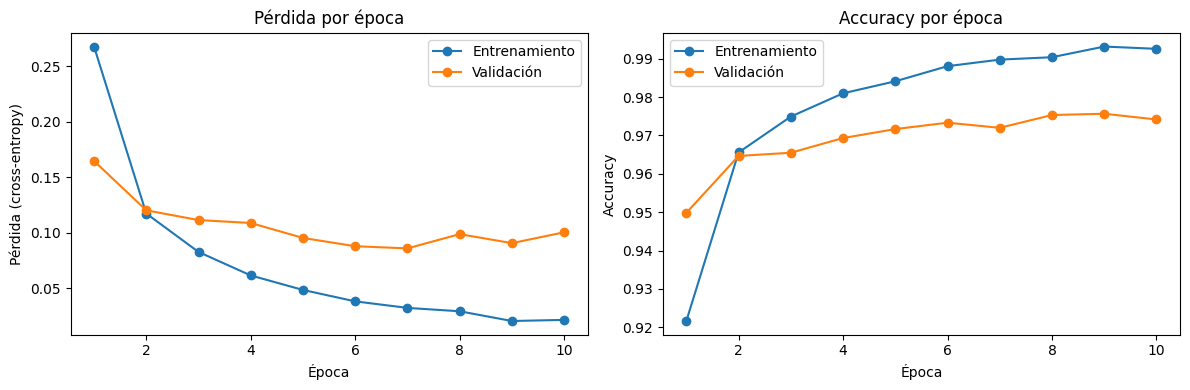

In [9]:
#guardamos el grafico
import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history["train_loss"], marker="o", label="Entrenamiento")
axes[0].plot(epochs_range, history["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida (cross-entropy)")
axes[0].legend()

axes[1].plot(epochs_range, history["train_acc"], marker="o", label="Entrenamiento")
axes[1].plot(epochs_range, history["val_acc"], marker="o", label="Validación")
axes[1].set_title("Accuracy por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig("curvas_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
#versiones
import sys
from importlib.metadata import version

print("Python:", sys.version.split()[0])
for paquete in ["torch", "torchvision", "numpy", "matplotlib"]:
    print(f"{paquete}=={version(paquete)}")

Python: 3.13.18
torch==2.11.0+cpu
torchvision==0.26.0+cpu
numpy==2.1.3
matplotlib==3.10.0
